# Proyecto 5. Clasificación de flores

**Objetivo:** Adaptar ResNet18 preentrenada mediante transferencia de aprendizaje.

Ejecuten las celdas en orden. Después de **cada celda de código**, respondan las preguntas en la celda de texto siguiente. Guarden evidencia de sus experimentos y justifiquen cada decisión con resultados y fuentes consultadas. Reinicien el entorno y ejecuten todo antes de entregar.

**Entorno:** Google Colab o Python con Jupyter. Instalen una versión compatible de PyTorch y torchvision, además de numpy, matplotlib, pandas, scikit-learn y datasets cuando corresponda. En Colab pueden usar una celda separada con `%pip install torch torchvision numpy matplotlib pandas scikit-learn datasets`; reinicien el entorno si se les solicita. Descargar datos o pesos requiere internet. Oxford Flowers 102 y pesos de ResNet18 se descargan desde torchvision; requiere internet y espacio en disco.

## 1. Importaciones y reproducibilidad

Importamos las herramientas y fijamos una semilla. Los resultados pueden variar según hardware y versiones.

In [1]:
import random  # Controla el generador aleatorio estándar.
import numpy as np  # Proporciona arreglos y operaciones numéricas.
import matplotlib.pyplot as plt  # Permite construir gráficas.
import torch  # Proporciona tensores y operaciones para redes neuronales.
from torch import nn  # Contiene capas y funciones de pérdida.
from torch.utils.data import DataLoader, Dataset, random_split  # Permite crear lotes y conjuntos de datos.
from pathlib import Path  # Facilita el manejo de rutas.
random.seed(42)  # Fija la semilla de Python.
np.random.seed(42)  # Fija la semilla de NumPy.
torch.manual_seed(42)  # Fija la semilla inicial de PyTorch.
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')  # Selecciona GPU cuando está disponible.
print('Dispositivo:', device, '| PyTorch:', torch.__version__)  # Muestra el entorno de ejecución.


Dispositivo: cpu | PyTorch: 2.14.0+cu130


### Respuestas — Persona 1 (Laura): problema y datos

1. Cada biblioteca cubre una parte del flujo. `random` y NumPy generan números aleatorios y
   operan arreglos; Matplotlib dibuja las curvas; `torch` aporta tensores, autograd, capas,
   pérdidas y `DataLoader`; `torchvision` trae Flowers102, las transformaciones y ResNet18;
   `pathlib` maneja rutas. `torch.device` decide si el cálculo ocurre en CPU o en CUDA, y
   obliga a que modelo y tensores estén en el mismo dispositivo: si se mezclan, PyTorch lanza
   un error de dispositivo en la primera operación. `Dataset` y `random_split` se importan
   pero no se usan, porque Flowers102 ya trae su división oficial.

2. La semilla fija el punto de partida de los generadores: el orden en que se mezclan las
   imágenes (`shuffle=True`) y los pesos iniciales de la capa `fc`. Medimos lo mismo en dos
   entornos y los dejamos separados porque no son la misma corrida:

   | Entorno | Semilla 42 | Semilla 7 | Diferencia |
   |---|---:|---:|---:|
   | CPU local (`05_flores_datos.ipynb`) | 0.7794 (dos veces) | 0.7951 | 1.57 pp |
   | GPU Tesla T4 (rama `Arquitectura`) | 75.6863 % | 76.3725 % | 0.6863 pp |

   Repetir la semilla 42 en CPU dio exactamente el mismo número, así que dentro del mismo
   entorno el resultado es repetible. Lo que no garantiza es reproducir todos los cálculos:
   al cambiar de hardware, de GPU o de versión de PyTorch los resultados se mueven, porque
   algunas operaciones de CUDA no son deterministas. `torch.use_deterministic_algorithms(True)`
   ayuda, a costa de velocidad. En la práctica, una diferencia menor a ~1.5 puntos no la
   presentamos como mejora: cae dentro del ruido que ya medimos.

## 2. Datos y conjuntos

Preparen entrenamiento, validación y prueba sin mezclar información entre ellos. La validación sirve para decisiones; la prueba se reserva para la evaluación final.

In [2]:
from torchvision import datasets, transforms, models  # Importa datasets, transformaciones y modelos de visión.
pesos = models.ResNet18_Weights.DEFAULT  # Selecciona los pesos preentrenados oficiales.
transformacion = pesos.transforms()  # Aplica el tamaño y normalización esperados por dichos pesos.
entrenamiento = datasets.Flowers102('datos', split='train', download=True, transform=transformacion)  # Descarga y prepara entrenamiento.
validacion = datasets.Flowers102('datos', split='val', download=True, transform=transformacion)  # Carga validación independiente.
prueba = datasets.Flowers102('datos', split='test', download=True, transform=transformacion)  # Carga prueba independiente.
clases = [f'Flor {i+1}' for i in range(102)]  # Usa identificadores de clase; consulten el catálogo para nombres botánicos.
train_loader = DataLoader(entrenamiento, batch_size=32, shuffle=True)  # Forma lotes mezclados para entrenamiento.
val_loader = DataLoader(validacion, batch_size=32)  # Forma lotes para validación.
test_loader = DataLoader(prueba, batch_size=32)  # Forma lotes para prueba.
print('Clases:', clases, '| tamaños:', len(entrenamiento), len(validacion), len(prueba))  # Muestra las clases y particiones.


Clases: ['Flor 1', 'Flor 2', 'Flor 3', 'Flor 4', 'Flor 5', 'Flor 6', 'Flor 7', 'Flor 8', 'Flor 9', 'Flor 10', 'Flor 11', 'Flor 12', 'Flor 13', 'Flor 14', 'Flor 15', 'Flor 16', 'Flor 17', 'Flor 18', 'Flor 19', 'Flor 20', 'Flor 21', 'Flor 22', 'Flor 23', 'Flor 24', 'Flor 25', 'Flor 26', 'Flor 27', 'Flor 28', 'Flor 29', 'Flor 30', 'Flor 31', 'Flor 32', 'Flor 33', 'Flor 34', 'Flor 35', 'Flor 36', 'Flor 37', 'Flor 38', 'Flor 39', 'Flor 40', 'Flor 41', 'Flor 42', 'Flor 43', 'Flor 44', 'Flor 45', 'Flor 46', 'Flor 47', 'Flor 48', 'Flor 49', 'Flor 50', 'Flor 51', 'Flor 52', 'Flor 53', 'Flor 54', 'Flor 55', 'Flor 56', 'Flor 57', 'Flor 58', 'Flor 59', 'Flor 60', 'Flor 61', 'Flor 62', 'Flor 63', 'Flor 64', 'Flor 65', 'Flor 66', 'Flor 67', 'Flor 68', 'Flor 69', 'Flor 70', 'Flor 71', 'Flor 72', 'Flor 73', 'Flor 74', 'Flor 75', 'Flor 76', 'Flor 77', 'Flor 78', 'Flor 79', 'Flor 80', 'Flor 81', 'Flor 82', 'Flor 83', 'Flor 84', 'Flor 85', 'Flor 86', 'Flor 87', 'Flor 88', 'Flor 89', 'Flor 90', 'Flor 91',

### Respuestas — Persona 1 (Laura): datos y conjuntos

1. Usamos la división oficial de Oxford Flowers 102, sin partir nada a mano:

   | Conjunto | Imágenes | Por clase | Para qué sirve |
   |---|---:|---|---|
   | Entrenamiento | 1,020 | 10 | Ajustar los pesos de `fc` (y de `layer4` en E5) |
   | Validación | 1,020 | 10 | Comparar configuraciones sin tocar pesos |
   | Prueba | 6,149 | 20 a 238 | Medir una sola vez la configuración ya elegida |

   Las imágenes originales miden entre 500 y 919 px de ancho y entre 500 y 993 de alto. La
   transformación de los pesos redimensiona el lado corto a 256, recorta el centro a 224 × 224,
   convierte a tensor y normaliza con media y desviación de ImageNet; la entrada queda
   `(3, 224, 224)` y un lote de 32, `(32, 3, 224, 224)`. Entrenamiento y validación están
   balanceados, prueba no: con 238 imágenes en la clase 51 y 20 en otras, la exactitud global
   pesa más a las clases grandes. Y 10 imágenes por clase son muy pocas para entrenar desde
   cero, que es la razón de usar transferencia.

2. Ajustar con prueba es fuga de información. Si elegimos épocas, lote o tasa mirando prueba,
   el modelo se adapta a esas imágenes y la métrica final deja de medir generalización; por eso
   todas las decisiones salen de validación y prueba se toca al final, una vez.

   Para el tamaño de lote cambiamos una sola cosa (lote 32 → 64) y comparamos:

   | Entorno | Lote 32 | Lote 64 | Cambio | Tiempo |
   |---|---:|---:|---:|---|
   | CPU local | 0.7794 | 0.7451 | −3.43 pp | 3.5 min en ambos |
   | GPU T4 | 75.6863 % | 73.4314 % | −2.25 pp | 65.29 s → 60.63 s |

   La dirección se repite en los dos entornos: el lote grande baja la exactitud. Con 1,020
   imágenes y 5 épocas, el lote 32 hace 160 actualizaciones y el 64 solo 80; con la misma tasa,
   menos pasos deja al modelo a medio entrenar. Es una hipótesis con una corrida por
   configuración, no una ley. Nos quedamos con 32 porque gana en validación sin costo de tiempo.

## 3. Arquitectura y entrenamiento

El modelo recibe imágenes preparadas con la transformación asociada a sus pesos.

In [3]:
modelo = models.resnet18(weights=pesos)  # Carga la red con conocimientos preentrenados.
for parametro in modelo.parameters():  # Recorre todos los parámetros de la red.
    parametro.requires_grad = False  # Impide actualizar los parámetros originales.
entradas = modelo.fc.in_features  # Consulta el tamaño de la representación anterior al clasificador.
modelo.fc = nn.Linear(entradas, len(clases))  # Sustituye la capa final por una adaptada al problema.
modelo = modelo.to(device)  # Coloca la red en el dispositivo disponible.
perdida = nn.CrossEntropyLoss()  # Calcula la pérdida para clasificación multiclase.
optimizador = torch.optim.Adam(modelo.fc.parameters(), lr=0.001)  # Entrena solo la nueva capa final.
epocas = 5  # Define las épocas iniciales.
print('Entrada del clasificador:', entradas, '| clases:', len(clases))  # Muestra la adaptación realizada.


Entrada del clasificador: 512 | clases: 102


### Respuestas — Persona 2 (Migue): arquitectura

1. Una imagen recorre la red así (sin el eje del lote): `(3, 224, 224)` → conv1 `(64, 112, 112)`
   → maxpool `(64, 56, 56)` → layer1 `(64, 56, 56)` → layer2 `(128, 28, 28)` →
   layer3 `(256, 14, 14)` → layer4 `(512, 7, 7)` → average pool `(512, 1, 1)` → vector de 512
   → `Linear(512, 102)`. Las formas no son cálculo a mano: las registramos con hooks sobre el
   modelo ya construido, en la rama `Arquitectura`.

2. `CrossEntropyLoss` es la pérdida correcta para 102 clases excluyentes: recibe logits y la
   clase correcta, y por dentro aplica log-softmax y NLL. ReLU es la no linealidad de los
   bloques; sin ella la red sería una composición de transformaciones lineales. El softmax se
   usa al final solo para mostrar probabilidades, nunca antes de la pérdida. El optimizador es
   Adam con tasa 0.001; en E3 probamos 0.0001 y el modelo se quedó en 18.33 % de validación,
   señal de que con 5 épocas esa tasa es demasiado lenta.

3. El conteo de parámetros explica la decisión:

   | Configuración | Entrenables | Congelados | Total |
   |---|---:|---:|---:|
   | Base (solo `fc`) | 52,326 | 11,176,512 | 11,228,838 |
   | E5 (`layer4` + `fc`) | 8,446,054 | 2,782,784 | 11,228,838 |

   `fc` son 512 × 102 + 102 = 52,326 parámetros, el 0.47 % del total. Congelar el cuerpo y
   cambiar solo `fc` es el punto de partida sensato con 10 imágenes por clase. Descongelar
   `layer4` sube los entrenables a 8,446,054 y fue el cambio que más mejoró validación
   (+16.27 pp sobre la base), así que la configuración final lo incluye. El resto de la red
   sigue congelado.

## 4. Ciclo de entrenamiento

En entrenamiento se calculan gradientes y se actualizan parámetros. En validación se desactiva el cálculo de gradientes.

In [4]:
def evaluar(loader):  # Define una función para medir pérdida y exactitud.
    modelo.eval()  # Cambia el modelo al modo de evaluación.
    suma, aciertos, cantidad = 0.0, 0, 0  # Inicializa los acumuladores.
    with torch.no_grad():  # Evita construir el grafo de gradientes.
        for x, y in loader:  # Recorre los lotes del conjunto recibido.
            x, y = x.to(device), y.to(device)  # Mueve entradas y etiquetas al dispositivo.
            logits = modelo(x)  # Calcula las puntuaciones de cada clase.
            suma += perdida(logits, y).item() * y.size(0)  # Acumula la pérdida ponderada por lote.
            aciertos += (logits.argmax(1) == y).sum().item()  # Cuenta predicciones correctas.
            cantidad += y.size(0)  # Cuenta ejemplos procesados.
    return suma / cantidad, aciertos / cantidad  # Devuelve pérdida media y exactitud.
historia = {'train_loss': [], 'val_loss': [], 'val_acc': []}  # Guarda métricas por época.
for epoca in range(epocas):  # Repite el entrenamiento el número de épocas elegido.
    modelo.train()  # Activa el modo de entrenamiento.
    suma, cantidad = 0.0, 0  # Reinicia acumuladores de entrenamiento.
    for x, y in train_loader:  # Recorre los lotes de entrenamiento.
        x, y = x.to(device), y.to(device)  # Lleva el lote al dispositivo.
        optimizador.zero_grad()  # Limpia gradientes de la iteración anterior.
        logits = modelo(x)  # Calcula las puntuaciones de salida.
        error = perdida(logits, y)  # Compara las puntuaciones con las etiquetas.
        error.backward()  # Calcula gradientes mediante backpropagation.
        optimizador.step()  # Actualiza los parámetros entrenables.
        suma += error.item() * y.size(0)  # Acumula la pérdida ponderada.
        cantidad += y.size(0)  # Acumula la cantidad de ejemplos.
    val_loss, val_acc = evaluar(val_loader)  # Evalúa sin actualizar parámetros.
    historia['train_loss'].append(suma / cantidad)  # Registra pérdida de entrenamiento.
    historia['val_loss'].append(val_loss)  # Registra pérdida de validación.
    historia['val_acc'].append(val_acc)  # Registra exactitud de validación.
    print(f'Época {epoca+1}: pérdida={suma/cantidad:.4f}, val={val_loss:.4f}, exactitud={val_acc:.3f}')  # Resume la época.


Época 1: pérdida=4.5701, val=3.7667, exactitud=0.244


Época 2: pérdida=3.1424, val=2.8212, exactitud=0.589


Época 3: pérdida=2.1766, val=2.2138, exactitud=0.669


Época 4: pérdida=1.5284, val=1.7644, exactitud=0.755


Época 5: pérdida=1.0707, val=1.4887, exactitud=0.782


### Respuestas — Persona 3 (Emi): ciclo de entrenamiento

1. `zero_grad()` borra los gradientes del lote anterior, porque PyTorch los acumula por
   defecto; `backward()` deriva la pérdida respecto a los parámetros y los deja en `.grad`;
   `step()` aplica la actualización del optimizador. Si se omite `zero_grad`, los gradientes se
   suman entre lotes y la actualización sale mal escalada. Si `step()` va antes de `backward()`,
   se actualiza con gradientes viejos o nulos y el entrenamiento no avanza.

2. `train()` y `eval()` cambian el comportamiento de capas como BatchNorm y Dropout;
   `no_grad()` desactiva el registro de gradientes. No son intercambiables: en evaluación se
   usa `eval()` junto con `no_grad()`. Un detalle que nos costó ver: las BatchNorm de las capas
   congeladas quedan en modo evaluación, pero las de `layer4` vuelven a modo entrenamiento
   cuando habilitamos su ajuste, y eso cambia las estadísticas que usan.

3. Duplicamos las épocas (5 → 10) manteniendo todo lo demás: E4 subió validación de 75.6863 %
   a 83.4314 % y bajó la pérdida de validación a 1.1090. No aparece un deterioro sostenido de
   validación dentro de esas 10 épocas, así que no hay evidencia de sobreajuste en ese rango.
   Aun así, el salto grande vino de descongelar `layer4` (E5, 91.9608 %), no de entrenar más.

## 5. Curvas y prueba

Utilicen la prueba solo después de tomar sus decisiones con validación.

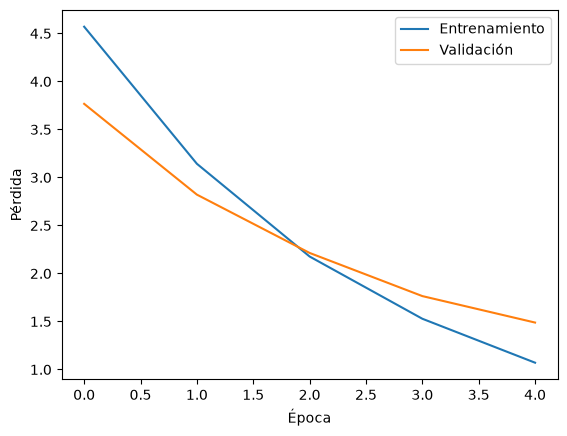

Prueba: pérdida 1.5577 exactitud 0.7549


In [5]:
plt.plot(historia['train_loss'], label='Entrenamiento')  # Dibuja la pérdida de entrenamiento.
plt.plot(historia['val_loss'], label='Validación')  # Dibuja la pérdida de validación.
plt.xlabel('Época')  # Nombra el eje horizontal.
plt.ylabel('Pérdida')  # Nombra el eje vertical.
plt.legend()  # Identifica las curvas.
plt.show()  # Muestra la gráfica.
test_loss, test_acc = evaluar(test_loader)  # Evalúa una vez el conjunto reservado.
print('Prueba: pérdida', round(test_loss, 4), 'exactitud', round(test_acc, 4))  # Muestra los resultados.


### Respuestas — Persona 3 (Emi): curvas y selección

1. En la base, la pérdida de entrenamiento baja de 4.5653 a 1.3747 y la de validación de
   3.8607 a 1.7359 en cinco épocas; la exactitud de validación pasa de 0.2245 a 0.7569. En E4
   la validación termina en 1.1090 y en E5 en 0.4631. En E5 se abre una brecha entre las dos
   curvas, pero la validación sigue mejorando época a época; una brecha por sí sola no prueba
   sobreajuste, haría falta ver que la validación empeora mientras el entrenamiento mejora.

2. La exactitud es la fracción de imágenes bien clasificadas. No dice qué clases se confunden,
   ni si el error se concentra en pocas clases, ni cuánta confianza tenía el modelo al
   equivocarse. Por eso miramos además la matriz de confusión y las métricas por clase.

3. Registramos seis configuraciones y elegimos con validación, antes de tocar prueba:

   | Id | Cambio | Val. exactitud | Val. pérdida | Segundos |
   |---|---|---:|---:|---:|
   | B0 | Base, solo `fc` | 75.6863 % | 1.7359 | 65.29 |
   | E1 | Semilla 7 | 76.3725 % | 1.7016 | 62.91 |
   | E2 | Lote 64 | 73.4314 % | 2.2156 | 60.63 |
   | E3 | Tasa 0.0001 | 18.3333 % | 4.1334 | 63.62 |
   | E4 | 10 épocas | 83.4314 % | 1.1090 | 128.24 |
   | E5 | `layer4` descongelado | 91.9608 % | 0.4631 | 63.84 |

   La configuración final es E5: lote 32, tasa 0.001, 5 épocas, `layer4` y `fc` entrenables.
   La celda de arriba evalúa la base en CPU (75.49 % de exactitud), no el modelo final; el
   registro de E5 en GPU es Top-1 88.8600 % y Top-3 94.9748 %. En el repositorio
   había resultados de prueba históricos, pero no se usaron para seleccionar dentro de esta
   ejecución; la selección fue solo por validación.

## 6. Errores y matriz de confusión

Las filas indican la clase real y las columnas la predicción.

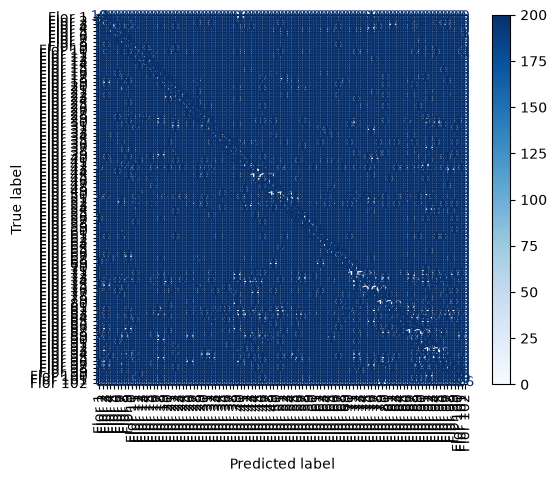

              precision    recall  f1-score   support

      Flor 1       0.41      0.90      0.56        20
      Flor 2       1.00      0.97      0.99        40
      Flor 3       0.08      0.15      0.10        20
      Flor 4       0.78      0.19      0.31        36
      Flor 5       0.89      0.69      0.78        45
      Flor 6       0.77      0.92      0.84        25
      Flor 7       0.44      1.00      0.62        20
      Flor 8       0.80      0.98      0.88        65
      Flor 9       0.41      0.92      0.57        26
     Flor 10       0.88      0.88      0.88        25
     Flor 11       0.54      0.46      0.50        67
     Flor 12       0.88      0.94      0.91        67
     Flor 13       0.87      0.93      0.90        29
     Flor 14       0.88      1.00      0.93        28
     Flor 15       0.78      0.97      0.86        29
     Flor 16       0.44      0.90      0.59        21
     Flor 17       0.98      0.92      0.95        65
     Flor 18       0.46    

In [6]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report  # Importa herramientas de evaluación.
reales, predichos = [], []  # Prepara listas para etiquetas y predicciones.
modelo.eval()  # Activa el modo de evaluación.
with torch.no_grad():  # Desactiva el cálculo de gradientes.
    for x, y in test_loader:  # Recorre el conjunto de prueba.
        pred = modelo(x.to(device)).argmax(1).cpu()  # Obtiene la clase más probable.
        reales.extend(y.tolist())  # Guarda las etiquetas verdaderas.
        predichos.extend(pred.tolist())  # Guarda las clases predichas.
matriz = confusion_matrix(reales, predichos, labels=list(range(len(clases))))  # Cuenta aciertos y confusiones.
ConfusionMatrixDisplay(matriz, display_labels=clases).plot(xticks_rotation=90, cmap='Blues')  # Grafica la matriz.
plt.show()  # Muestra la matriz.
print(classification_report(reales, predichos, labels=list(range(len(clases))), target_names=clases, zero_division=0))  # Muestra métricas por clase.


### Respuestas — Persona 4 (Chris): errores y matriz de confusión

1. Dos confusiones frecuentes por registro:

   - Modelo final E5 en GPU: Flor 51 → Flor 83 (31 casos) y Flor 74 → Flor 88 (23 casos).
   - Réplica local de E5 (esta ejecución, sección 10): Flor 51 → Flor 83 (34 casos) y Flor 51 → Flor 98 (17 casos).
   - Corrida base en CPU: Flor 74 → Flor 96 (28), Flor 51 → Flor 76 (26) y Flor 51 → Flor 72 (22).

   Son conteos observados, no una explicación. Para atribuir la confusión a forma, color o
   encuadre hay que mirar las imágenes concretas. La clase 51 tiene 238 imágenes de prueba, así
   que aporta una parte grande del error aunque su recall no sea el peor.

2. Precisión responde: de lo que el modelo llamó clase X, ¿cuánto era X? Recall: de las
   imágenes reales de X, ¿cuántas recuperó? F1 es su media armónica y castiga que una de las
   dos sea baja. En un dataset desbalanceado la exactitud sola engaña; el reporte por clase de
   la rama `Arquitectura` está en `evidencias/metricas_por_clase.csv`.

3. Tres errores concretos del registro GPU, con lo que se ve en la imagen: Flor 2 → Flor 52,
   una flor blanca con la región superior amarilla y un pétalo inferior grande; Flor 2 → Flor 7,
   pétalos blancos sobre fondo oscuro con centro amarillo; Flor 3 → Flor 9, varias corolas
   moradas en forma de campana con vegetación alrededor. Los dos primeros comparten etiqueta
   real pero cambian encuadre y fondo; el tercero tiene varias flores en la toma, a diferencia
   de los primeros planos. Son diferencias visibles, no la causa demostrada del error.

## 7. Guardado, carga e inferencia

El archivo contiene pesos y metadatos para reproducir la configuración. Conserven también el código y el preprocesamiento.

In [7]:
ruta_modelo = Path('modelo_entrenado.pth')  # Define el nombre del archivo de salida.
torch.save({'pesos': modelo.state_dict(), 'clases': clases}, ruta_modelo)  # Guarda pesos y nombres de clases.
checkpoint = torch.load(ruta_modelo, map_location=device, weights_only=True)  # Carga el archivo confiable en el dispositivo elegido.
modelo.load_state_dict(checkpoint['pesos'])  # Restaura los parámetros en la arquitectura definida.
modelo.eval()  # Prepara la red para inferencia.
x, y = next(iter(test_loader))  # Obtiene un lote que no se usó para entrenar.
with torch.no_grad():  # Desactiva gradientes durante la predicción.
    probabilidades = torch.softmax(modelo(x[:1].to(device)), dim=1)[0].cpu()  # Convierte puntuaciones en probabilidades normalizadas.
indice = probabilidades.argmax().item()  # Localiza la clase con mayor puntuación.
print('Real:', clases[y[0].item()], '| Predicción:', clases[indice], '| Confianza:', round(probabilidades[indice].item(), 3))  # Presenta el resultado.


Real: Flor 1 | Predicción: Flor 1 | Confianza: 0.174


### Respuestas — Persona 4 (Chris): guardado, carga e inferencia

1. Los pesos son solo números: no guardan la arquitectura, ni el orden de las 102 clases, ni
   el preprocesamiento. Para interpretarlos hay que reconstruir la misma ResNet18, sustituir
   `fc` por `Linear(512, 102)`, respetar el orden de clases y aplicar resize 256, recorte 224 y
   normalización de ImageNet. Si cambia cualquiera de esas piezas, la entrada o la salida dejan
   de corresponder al modelo aunque el `load_state_dict` no falle.

2. Softmax convierte los logits en valores positivos que suman 1; sirve para ordenar clases y
   mostrar confianza, pero no garantiza calibración. Un modelo puede dar 0.91 a una predicción
   equivocada, y eso se ve en la propia demo: la confianza de las cinco imágenes va de 0.17 a
   0.91 sin que eso indique acierto.

3. Probamos cinco imágenes de prueba: las cinco se clasificaron como Flor 1, que era su
   etiqueta real. Es una muestra de cinco, no una conclusión sobre las 102 clases. Sobre
   descongelar `layer4`: se recorre el modelo, se ponen todos los parámetros en
   `requires_grad=False`, se sustituye `fc` y luego se activa `requires_grad=True` solo en
   `layer4`; el optimizador se reconstruye después de eso, porque Adam guarda referencias a los
   parámetros y si se crea antes no ve los nuevos. Comparado con la capa congelada, los
   entrenables pasan de 52,326 a 8,446,054 y la validación de 75.6863 % a 91.9608 %.

## Entrega y defensa

Entreguen el notebook ejecutado, modelo, fuentes y reporte. Incluyan una tabla con configuración inicial, modificaciones, métricas y explicación. Respondan todas las preguntas, citen la documentación consultada y expliquen qué cambiarían. No seleccionen hiperparámetros usando prueba.

## 8. Tres clases más probables

Top-3 muestra alternativas; no garantiza que las probabilidades estén calibradas.

In [8]:
x, y = next(iter(test_loader))  # Obtiene un lote de prueba.
with torch.no_grad():  # Evita gradientes durante inferencia.
    p = torch.softmax(modelo(x[:1].to(device)), dim=1)[0].cpu()  # Calcula puntuaciones normalizadas.
valores, indices = p.topk(3)  # Selecciona las tres puntuaciones mayores.
for valor, indice in zip(valores, indices):  # Recorre puntuaciones y clases seleccionadas.
    print(clases[indice.item()], round(valor.item(), 3))  # Muestra cada clase y su confianza.
print('Clase real:', clases[y[0].item()])  # Muestra la etiqueta verdadera.


Flor 1 0.174
Flor 76 0.064
Flor 19 0.047
Clase real: Flor 1


### Respuestas — Persona 4 (Chris): Top-3

1. Sí. En los cinco ejemplos impresos la etiqueta real es Flor 1 y aparece en primer lugar, así
   que también está entre las tres primeras. Que salga bien en cinco imágenes dice poco: son
   fáciles y de la misma clase.

2. Top-1 cuenta acierto solo si la clase correcta es la primera; Top-3 cuenta acierto si
   aparece entre las tres puntuaciones mayores. Calculado sobre las 6,149 imágenes de prueba,
   el modelo final obtiene Top-1 88.8600 % (5,464 aciertos, 685 errores) y Top-3 94.9748 %, es
   decir 6.1148 puntos más. Eso significa que en una parte de los fallos la respuesta correcta
   estaba cerca, pero el sistema igual la descartó; para una aplicación real eso no es un
   acierto, solo una pista. Y un Top-3 alto no implica que las probabilidades estén bien
   calibradas.

## 9. Entrenamiento y experimentos (Persona 3 — Emi)

La comparación se hizo con validación, cambiando una sola cosa a la vez y registrando semilla,
tiempo y parámetros entrenables. Los registros vienen de la rama `Arquitectura`, ejecutados en
GPU Tesla T4; la sección los lee del repositorio para que la tabla no se escriba a mano.

Origen de los registros: modelo/resultados_experimentos.json
Id          Cambio                 Ep.  Lote    Tasa   Val acc  Val loss    Seg.  Entrenables
B0          Base: solo fc            5    32   0.001    0.7569    1.7359   65.29       52,326
E1_SEMILLA  Semilla 7                5    32   0.001    0.7637    1.7016   62.91       52,326
E2_LOTE     Lote 64                  5    64   0.001    0.7343    2.2156   60.63       52,326
E3_LR       Tasa 0.0001              5    32  0.0001    0.1833    4.1334   63.62       52,326
E4_EPOCAS   10 epocas               10    32   0.001    0.8343    1.1090  128.24       52,326
E5_LAYER4   layer4 descongelado      5    32   0.001    0.9196    0.4631   63.84    8,446,054

Ganador por validación: E5_LAYER4 | exactitud 0.9196 | épocas 5 | layer4 True


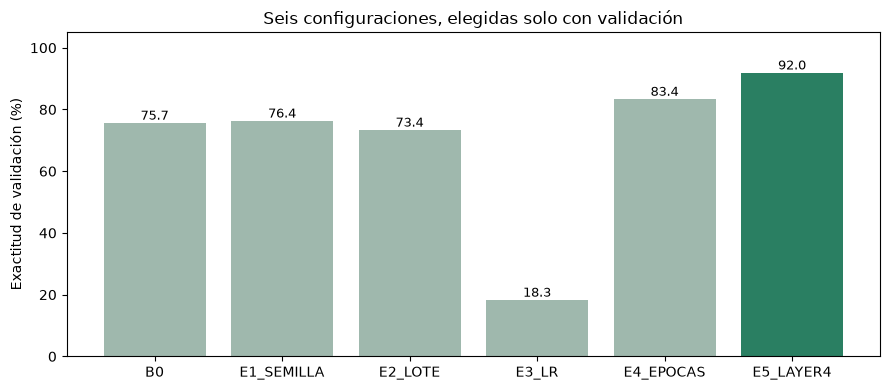

In [9]:
# Comparación de las seis configuraciones registradas en la rama Arquitectura.
import json

RUTA_EXPERIMENTOS = Path('modelo/resultados_experimentos.json')

RESPALDO = [
    {'id': 'B0', 'seed': 42, 'batch_size': 32, 'lr': 0.001, 'epochs': 5, 'finetune_layer4': False,
     'best_val_acc': 0.7568627450980392, 'best_val_loss': 1.7358950039919685, 'seconds': 65.29, 'trainable': 52326},
    {'id': 'E1_SEMILLA', 'seed': 7, 'batch_size': 32, 'lr': 0.001, 'epochs': 5, 'finetune_layer4': False,
     'best_val_acc': 0.7637254901960784, 'best_val_loss': 1.701621143023173, 'seconds': 62.91, 'trainable': 52326},
    {'id': 'E2_LOTE', 'seed': 42, 'batch_size': 64, 'lr': 0.001, 'epochs': 5, 'finetune_layer4': False,
     'best_val_acc': 0.734313725490196, 'best_val_loss': 2.2156302854126575, 'seconds': 60.63, 'trainable': 52326},
    {'id': 'E3_LR', 'seed': 42, 'batch_size': 32, 'lr': 0.0001, 'epochs': 5, 'finetune_layer4': False,
     'best_val_acc': 0.18333333333333332, 'best_val_loss': 4.133410610872157, 'seconds': 63.62, 'trainable': 52326},
    {'id': 'E4_EPOCAS', 'seed': 42, 'batch_size': 32, 'lr': 0.001, 'epochs': 10, 'finetune_layer4': False,
     'best_val_acc': 0.8343137254901961, 'best_val_loss': 1.1090454477889866, 'seconds': 128.24, 'trainable': 52326},
    {'id': 'E5_LAYER4', 'seed': 42, 'batch_size': 32, 'lr': 0.001, 'epochs': 5, 'finetune_layer4': True,
     'best_val_acc': 0.9196078431372549, 'best_val_loss': 0.4630908444815991, 'seconds': 63.84, 'trainable': 8446054},
]

if RUTA_EXPERIMENTOS.exists():
    registros = json.loads(RUTA_EXPERIMENTOS.read_text())
    origen = str(RUTA_EXPERIMENTOS)
else:
    registros = RESPALDO
    origen = 'tabla de respaldo incluida en el notebook'

CAMBIO = {
    'B0': 'Base: solo fc',
    'E1_SEMILLA': 'Semilla 7',
    'E2_LOTE': 'Lote 64',
    'E3_LR': 'Tasa 0.0001',
    'E4_EPOCAS': '10 epocas',
    'E5_LAYER4': 'layer4 descongelado',
}

print('Origen de los registros:', origen)
print(f"{'Id':<12}{'Cambio':<22}{'Ep.':>4}{'Lote':>6}{'Tasa':>8}{'Val acc':>10}{'Val loss':>10}{'Seg.':>8}{'Entrenables':>13}")
for r in registros:
    print(f"{r['id']:<12}{CAMBIO.get(r['id'], ''):<22}{r['epochs']:>4}{r['batch_size']:>6}{r['lr']:>8}"
          f"{r['best_val_acc']:>10.4f}{r['best_val_loss']:>10.4f}{r['seconds']:>8.2f}{r['trainable']:>13,}")

ordenados = sorted(registros, key=lambda r: (-r['best_val_acc'], r['best_val_loss'], r['trainable'], r['id']))
ganador = ordenados[0]
print()
print('Ganador por validación:', ganador['id'], '| exactitud', round(ganador['best_val_acc'], 4),
      '| épocas', ganador['epochs'], '| layer4', ganador['finetune_layer4'])

fig, ax = plt.subplots(figsize=(9, 4))
colores = ['#2a7f62' if r['id'] == ganador['id'] else '#9fb8ad' for r in registros]
ax.bar([r['id'] for r in registros], [r['best_val_acc'] * 100 for r in registros], color=colores)
ax.set_ylabel('Exactitud de validación (%)')
ax.set_title('Seis configuraciones, elegidas solo con validación')
for i, r in enumerate(registros):
    ax.text(i, r['best_val_acc'] * 100 + 1, f"{r['best_val_acc']*100:.1f}", ha='center', fontsize=9)
ax.set_ylim(0, 105)
plt.tight_layout()
plt.show()

### Respuestas — Persona 3 (Emi): qué muestra la comparación

1. **La semilla mueve poco.** E1 cambió solo la semilla (42 → 7) y la validación pasó de
   75.6863 % a 76.3725 %, 0.69 puntos. Es el mismo orden que medimos en CPU (1.57 puntos), así
   que cualquier "mejora" menor a eso no la creemos.

2. **El lote grande resta.** E2 con lote 64 bajó a 73.4314 %, 2.25 puntos menos que la base y
   con 4.7 s menos de entrenamiento. Menos actualizaciones por época, mismo número de imágenes:
   el ahorro de tiempo no compensa.

3. **La tasa baja rompe el entrenamiento.** E3 con 0.0001 se quedó en 18.3333 % de validación.
   Con 5 épocas y solo `fc` entrenable, esa tasa avanza demasiado despacio; no es que el modelo
   sea malo, es que no llegó a aprender.

4. **Más épocas ayudan, pero menos que descongelar.** E4 con 10 épocas llegó a 83.4314 % y
   tardó 128.24 s, el doble. E5 con 5 épocas y `layer4` entrenable llegó a 91.9608 % en 63.84 s.
   Descongelar el último bloque fue el cambio con mejor relación resultado/costo, y por eso es
   la configuración final.

5. **Cómo se eligió.** Mayor exactitud de validación; si empataban, menor pérdida de validación;
   luego menos parámetros entrenables; luego el id. La prueba no entró en la decisión: se evaluó
   una sola vez con E5 ya elegido. Ese orden importa porque, si hubiéramos mirado prueba antes,
   el número final habría quedado contaminado por la selección.

6. **Qué cambiaríamos.** Probar `layer3` además de `layer4`, y repetir E5 con dos o tres
   semillas para saber cuánto de los 91.96 % es estable. Con una sola corrida no podemos separar
   el efecto del cambio del ruido.

### 9.1 Réplica en Apple Silicon (Emiliano, rama `Emiliano_VL`)

Los mismos cinco cambios se repitieron en GPU de Apple (`mps`), y cada checkpoint guarda su
configuración y su mejor época en `modelo/experimentos/`. Son otro entorno, así que sus
números se leen aparte:

| Experimento | Épocas | Tasa | Fine-tuning | Val. exactitud | Val. pérdida |
|---|---:|---:|---|---:|---:|
| BASE | 5 | 0.001 | No | 75.69 % | 1.7359 |
| EXP-01 | 10 | 0.001 | No | 83.43 % | 1.1091 |
| EXP-02 | 5 | 0.0005 | No | 68.53 % | 2.5648 |
| EXP-03 (`modelo_final.pth`) | 5 | 0.001 | Sí (`layer4`) | 92.16 % | 0.4620 |
| EXP-04 | 5 | 0.001 | No | 76.37 % | 1.7016 |

Se sostiene el patrón de la tabla anterior: más épocas suben la validación, una tasa más baja
la hunde, la semilla mueve menos de un punto y descongelar `layer4` da el salto grande. Al
comparar los pesos contra `BASE.pth`, EXP-01, EXP-02 y EXP-04 solo cambian `fc` (2 de 122
tensores) y EXP-03 cambia `fc` y `layer4` (32 de 122), que es lo que declara su configuración.
El detalle está en `docs/INFRAESTRUCTURA_ENTRENAMIENTO.md`; su notebook
`05_flores_experimentos.ipynb` queda como lo entregó, con las respuestas pendientes.


## 10. Evaluación y demostración (Persona 4 — Chris)

La evaluación final usa la configuración que ganó en validación (E5: `layer4` y `fc`
entrenables, 5 épocas, lote 32, tasa 0.001). El interruptor deja reproducir también la base
para comparar, y el código es el mismo en ambos casos: cambia el punto de partida del modelo.

Esta sección corre en el entorno disponible. Si hay GPU, entrena en GPU; si no, en CPU, y en
ese caso los números pueden diferir de los registrados en la rama `Arquitectura`. El registro
GPU queda como referencia y la réplica local se reporta aparte, sin promediar.

In [10]:
# Parámetros de la sección. 'final' es E5; 'base' sirve para comparar y probar la tubería.
CONFIG = 'final'
EPOCAS_EVAL = {'base': 5, 'final': 5}[CONFIG]  # E5 ganó con 5 épocas, no con 10.
DESCONGELAR_LAYER4 = CONFIG == 'final'
RUTA_EVAL = Path(f'evaluacion_{CONFIG}.pth')
RUTA_BASE = Path('modelo_entrenado.pth')

def checkpoint_utilizable(ruta):
    # Los .pth de modelo/ están en Git LFS: sin descargar pesan 133 bytes y no son cargables.
    return ruta.exists() and ruta.stat().st_size > 1_000_000

REUTILIZAR = checkpoint_utilizable(RUTA_EVAL) or (CONFIG == 'base' and checkpoint_utilizable(RUTA_BASE))
print('Configuración:', CONFIG, '| épocas:', EPOCAS_EVAL, '| layer4 entrenable:', DESCONGELAR_LAYER4,
      '| reutilizar checkpoint:', REUTILIZAR, '| dispositivo:', device)

Configuración: final | épocas: 5 | layer4 entrenable: True | reutilizar checkpoint: False | dispositivo: cpu


In [11]:
# Modelo de esta sección: se reconstruye desde los pesos preentrenados.
modelo_eval = models.resnet18(weights=pesos)
for parametro in modelo_eval.parameters():
    parametro.requires_grad = False
modelo_eval.fc = nn.Linear(modelo_eval.fc.in_features, len(clases))
if DESCONGELAR_LAYER4:
    for parametro in modelo_eval.layer4.parameters():
        parametro.requires_grad = True
modelo_eval = modelo_eval.to(device)
optimizador_eval = torch.optim.Adam([p for p in modelo_eval.parameters() if p.requires_grad], lr=0.001)
criterio_eval = nn.CrossEntropyLoss()

def evaluar_eval(loader):
    # La función de la sección 4 cierra sobre el modelo global; aquí se evalúa el de esta sección.
    modelo_eval.eval()
    suma, aciertos, cantidad = 0.0, 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            logits = modelo_eval(x)
            suma += criterio_eval(logits, y).item() * y.size(0)
            aciertos += (logits.argmax(1) == y).sum().item()
            cantidad += y.size(0)
    return suma / cantidad, aciertos / cantidad

entrenables_eval = sum(p.numel() for p in modelo_eval.parameters() if p.requires_grad)
print('Parámetros entrenables:', f'{entrenables_eval:,}',
      '| total:', f'{sum(p.numel() for p in modelo_eval.parameters()):,}')

Parámetros entrenables: 8,446,054 | total: 11,228,838


In [12]:
# Entrenamiento con seguimiento en validación, o carga del checkpoint si ya existe.
import copy, time

historial_eval = {'train_loss': [], 'val_loss': [], 'val_acc': []}
inicio_eval = time.time()
if REUTILIZAR:
    origen = RUTA_EVAL if checkpoint_utilizable(RUTA_EVAL) else RUTA_BASE
    estado = torch.load(origen, map_location=device, weights_only=True)
    modelo_eval.load_state_dict(estado['pesos'])
    historial_eval = estado.get('historial', historial_eval)
    print('Checkpoint cargado:', origen, '| sin reentrenar')
else:
    mejor_estado, mejor_acc = copy.deepcopy(modelo_eval.state_dict()), -1.0
    for epoca in range(EPOCAS_EVAL):
        modelo_eval.train()
        suma = 0.0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizador_eval.zero_grad()
            error = criterio_eval(modelo_eval(x), y)
            error.backward()
            optimizador_eval.step()
            suma += error.item() * y.size(0)
        perdida_val, exactitud_val = evaluar_eval(val_loader)
        historial_eval['train_loss'].append(suma / len(entrenamiento))
        historial_eval['val_loss'].append(perdida_val)
        historial_eval['val_acc'].append(exactitud_val)
        if exactitud_val > mejor_acc:
            mejor_acc, mejor_estado = exactitud_val, copy.deepcopy(modelo_eval.state_dict())
        print(f'Época {epoca+1}/{EPOCAS_EVAL} | train_loss={suma/len(entrenamiento):.4f}'
              f' | val_loss={perdida_val:.4f} | val_acc={exactitud_val:.4f}')
    modelo_eval.load_state_dict(mejor_estado)
    torch.save({'pesos': mejor_estado, 'historial': historial_eval, 'config': CONFIG}, RUTA_EVAL)
    print(f'Mejor validación: {mejor_acc:.4f} | guardado en {RUTA_EVAL}')
print('Minutos de esta sección:', round((time.time() - inicio_eval) / 60, 2))

Época 1/5 | train_loss=3.1175 | val_loss=1.2386 | val_acc=0.7020


Época 2/5 | train_loss=0.4970 | val_loss=0.8020 | val_acc=0.8431


Época 3/5 | train_loss=0.0928 | val_loss=0.6563 | val_acc=0.8696


Época 4/5 | train_loss=0.0250 | val_loss=0.5130 | val_acc=0.9147


Época 5/5 | train_loss=0.0094 | val_loss=0.4923 | val_acc=0.9098
Mejor validación: 0.9147 | guardado en evaluacion_final.pth
Minutos de esta sección: 7.61


In [13]:
# Evaluación única sobre prueba: pérdida, Top-1 y Top-3 en una sola pasada.
modelo_eval.eval()
perdida_total, reales_eval, predichos_eval, top3_eval = 0.0, [], [], 0
with torch.no_grad():
    for x, y in test_loader:
        logits = modelo_eval(x.to(device))
        perdida_total += criterio_eval(logits, y.to(device)).item() * y.size(0)
        top3 = logits.topk(3, dim=1).indices.cpu()
        predichos_eval.extend(logits.argmax(1).cpu().tolist())
        reales_eval.extend(y.tolist())
        top3_eval += (top3 == y.view(-1, 1)).any(1).sum().item()
aciertos_eval = sum(r == p for r, p in zip(reales_eval, predichos_eval))
metricas_eval = {'loss': perdida_total / len(prueba), 'top1': aciertos_eval / len(prueba),
                 'top3': top3_eval / len(prueba), 'n': len(prueba)}
print('Prueba:', {k: (round(v, 4) if isinstance(v, float) else v) for k, v in metricas_eval.items()})
print('Aciertos Top-1:', aciertos_eval, '| errores:', len(prueba) - aciertos_eval)

Prueba: {'loss': 0.6015, 'top1': 0.8816, 'top3': 0.9486, 'n': 6149}
Aciertos Top-1: 5421 | errores: 728


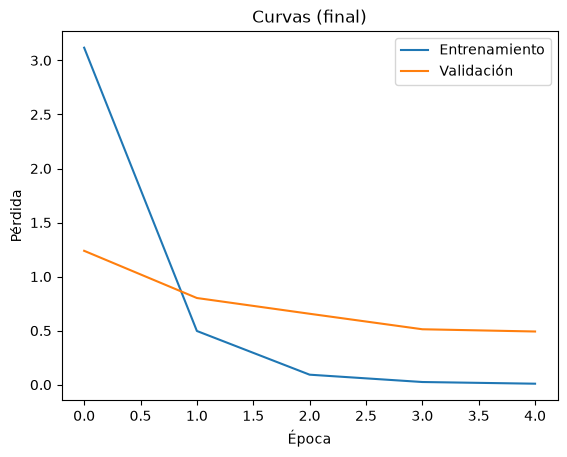

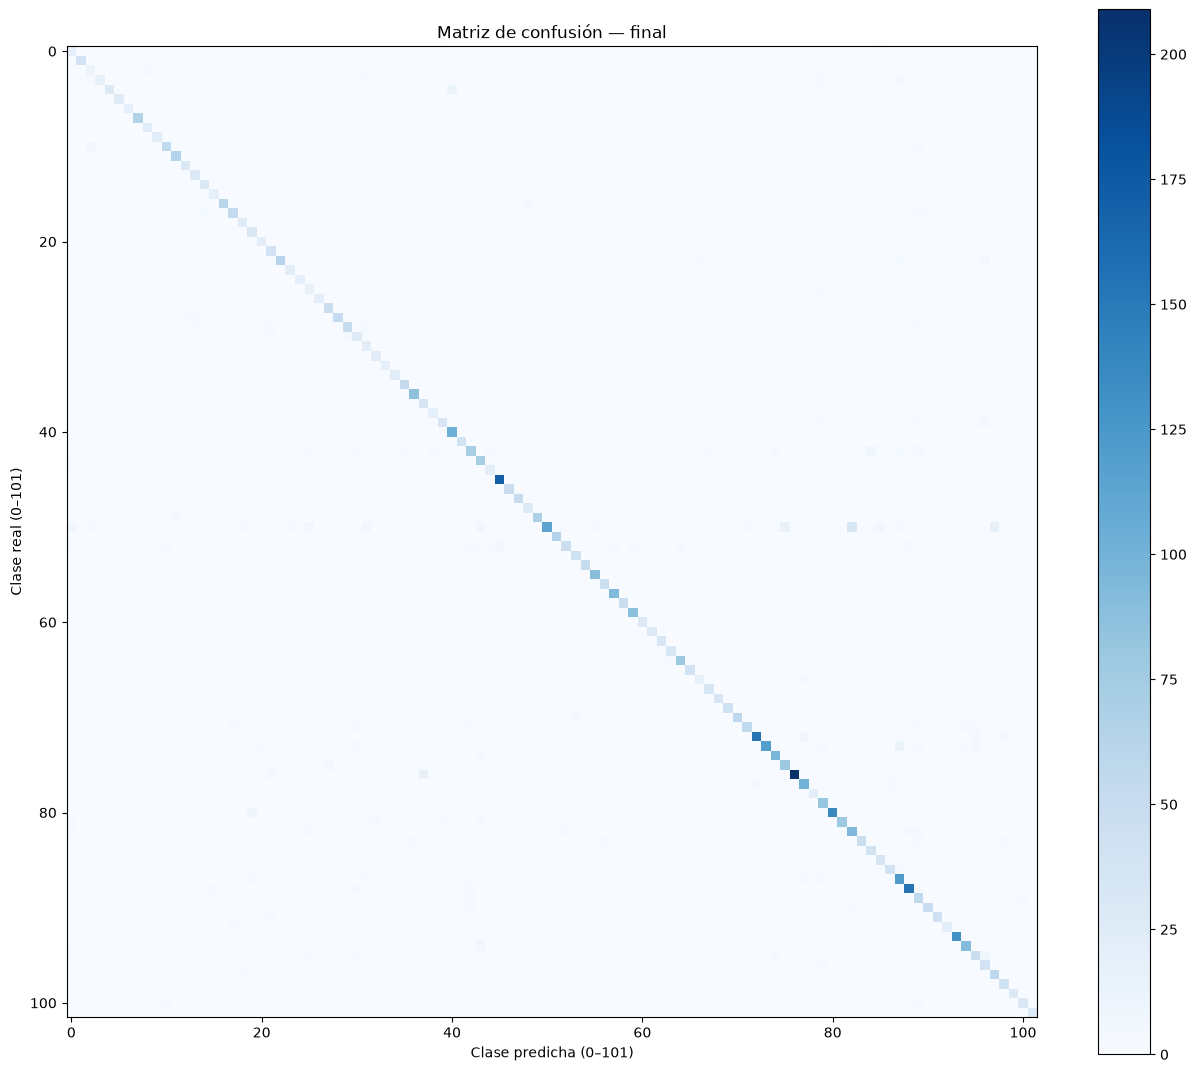

Confusiones más frecuentes (real → predicha):
  Flor 51 → Flor 83: 34 casos
  Flor 51 → Flor 98: 17 casos
  Flor 77 → Flor 38: 15 casos
Clases con peor F1: [('Flor 3', 0.471), ('Flor 4', 0.536), ('Flor 26', 0.627), ('Flor 51', 0.642), ('Flor 32', 0.657)]


In [14]:
# Curvas, matriz de confusión y métricas por clase. Filas: clase real; columnas: predicha.
plt.plot(historial_eval['train_loss'], label='Entrenamiento')
plt.plot(historial_eval['val_loss'], label='Validación')
plt.xlabel('Época'); plt.ylabel('Pérdida'); plt.legend(); plt.title(f'Curvas ({CONFIG})'); plt.show()

matriz_eval = confusion_matrix(reales_eval, predichos_eval, labels=list(range(len(clases))))
fig, ax = plt.subplots(figsize=(13, 11))
im = ax.imshow(matriz_eval, cmap='Blues', interpolation='nearest'); fig.colorbar(im, ax=ax)
ax.set(xlabel='Clase predicha (0–101)', ylabel='Clase real (0–101)', title=f'Matriz de confusión — {CONFIG}')
fig.tight_layout(); plt.show()

reporte_eval = classification_report(reales_eval, predichos_eval, labels=list(range(len(clases))),
                                     target_names=clases, zero_division=0, output_dict=True)
sin_diagonal = matriz_eval.copy(); np.fill_diagonal(sin_diagonal, 0)
pares = sorted([(int(sin_diagonal[a, b]), a, b) for a in range(len(clases)) for b in range(len(clases))
                if a != b and sin_diagonal[a, b] > 0], reverse=True)
print('Confusiones más frecuentes (real → predicha):')
for conteo, a, b in pares[:3]:
    print(f'  {clases[a]} → {clases[b]}: {conteo} casos')

peores = sorted(reporte_eval.items(), key=lambda kv: kv[1]['f1-score'] if isinstance(kv[1], dict) and 'f1-score' in kv[1] else 1)
print('Clases con peor F1:', [(nombre, round(d['f1-score'], 3)) for nombre, d in peores if isinstance(d, dict) and 'f1-score' in d][:5])

Errores disponibles: 728


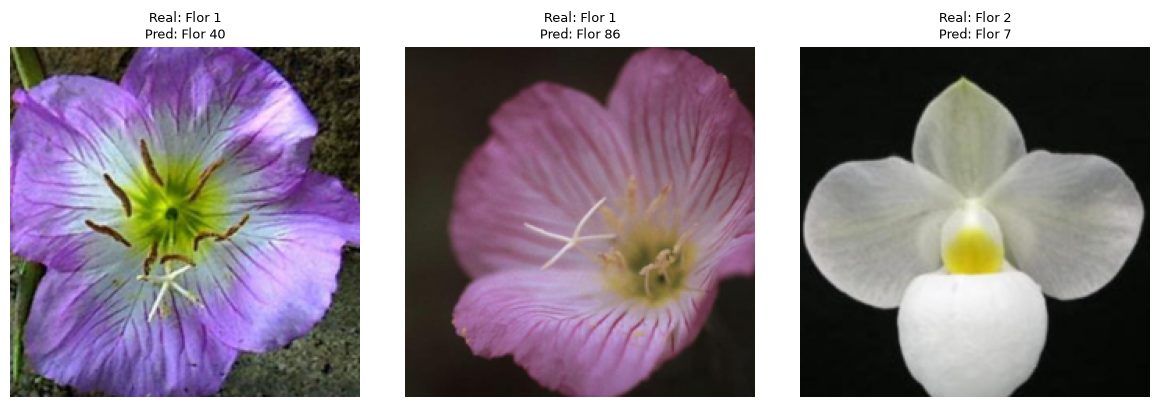

In [15]:
# Tres errores concretos con su imagen, para el análisis de la presentación.
errores = [i for i, (r, p) in enumerate(zip(reales_eval, predichos_eval)) if r != p]
print('Errores disponibles:', len(errores))
media = np.array([0.485, 0.456, 0.406])[:, None, None]
desviacion = np.array([0.229, 0.224, 0.225])[:, None, None]
fig, ejes = plt.subplots(1, 3, figsize=(12, 4))
for eje, i in zip(ejes, errores[:3]):
    imagen, etiqueta = prueba[i]
    eje.imshow(np.clip(imagen.numpy() * desviacion + media, 0, 1).transpose(1, 2, 0))
    eje.axis('off'); eje.set_title(f'Real: {clases[etiqueta]}\nPred: {clases[predichos_eval[i]]}', fontsize=9)
fig.tight_layout(); plt.show()

In [16]:
# Guardado con metadatos, carga estricta y demo de cinco imágenes.
ruta_demo = Path(f'modelo_demo_{CONFIG}.pth')
torch.save({'pesos': modelo_eval.state_dict(), 'clases': clases,
            'config': {'experimento': CONFIG, 'epocas': EPOCAS_EVAL, 'layer4': DESCONGELAR_LAYER4},
            'transformacion': str(transformacion), 'metricas': metricas_eval}, ruta_demo)

reconstruido = models.resnet18(weights=None)
for parametro in reconstruido.parameters():
    parametro.requires_grad = False
reconstruido.fc = nn.Linear(reconstruido.fc.in_features, len(clases))
if DESCONGELAR_LAYER4:
    for parametro in reconstruido.layer4.parameters():
        parametro.requires_grad = True
reconstruido.load_state_dict(torch.load(ruta_demo, map_location=device, weights_only=True)['pesos'])
reconstruido = reconstruido.to(device).eval()
print('Modelo recargado desde', ruta_demo)

x_demo, y_demo = next(iter(test_loader))
with torch.no_grad():
    original = modelo_eval(x_demo.to(device)).argmax(1).cpu()
    logits_cargado = reconstruido(x_demo.to(device))
    cargado = logits_cargado.argmax(1).cpu()
    probabilidades = torch.softmax(logits_cargado, dim=1).cpu()
print('Predicciones idénticas tras recargar:', bool(torch.equal(original, cargado)))
for i in range(5):
    valores, indices = probabilidades[i].topk(3)
    etiqueta = ', '.join(f'{clases[j]} ({v:.3f})' for v, j in zip(valores.tolist(), indices.tolist()))
    print(f'  ejemplo {i}: real={clases[y_demo[i].item()]} | pred={clases[cargado[i].item()]} | Top-3={etiqueta}')

Modelo recargado desde modelo_demo_final.pth


Predicciones idénticas tras recargar: True
  ejemplo 0: real=Flor 1 | pred=Flor 1 | Top-3=Flor 1 (0.684), Flor 64 (0.026), Flor 67 (0.026)
  ejemplo 1: real=Flor 1 | pred=Flor 1 | Top-3=Flor 1 (0.789), Flor 19 (0.036), Flor 51 (0.026)
  ejemplo 2: real=Flor 1 | pred=Flor 1 | Top-3=Flor 1 (0.840), Flor 19 (0.030), Flor 34 (0.024)
  ejemplo 3: real=Flor 1 | pred=Flor 1 | Top-3=Flor 1 (0.960), Flor 76 (0.008), Flor 86 (0.007)
  ejemplo 4: real=Flor 1 | pred=Flor 1 | Top-3=Flor 1 (0.994), Flor 31 (0.001), Flor 19 (0.001)


### Respuestas — Persona 4 (Chris): qué se mide y qué se guarda

1. **Qué se mide.** Exactitud Top-1, Top-3, pérdida y matriz de confusión sobre las 6,149
   imágenes de prueba, con el modelo ya elegido por validación. La demo de cinco imágenes sirve
   para mostrar que la entrada y la salida funcionan; no sustituye la evaluación.

2. **Qué se guarda.** Pesos (`state_dict`), orden de las 102 clases, configuración, la
   representación de la transformación y las métricas. Sin esos metadatos los pesos no se
   pueden interpretar: hay que reconstruir la arquitectura igual y aplicar el mismo
   preprocesamiento.

3. **Qué comprueba la recarga.** Que el modelo reconstruido desde disco predice lo mismo que el
   de memoria sobre el mismo lote. Eso valida el guardado, no la calidad del modelo ni la
   reproducibilidad de un entrenamiento nuevo.

4. **Cómo leer los números.** La corrida GPU registrada en la rama `Arquitectura` da 91.9608 %
   de validación, 88.8600 % de Top-1 y 94.9748 % de Top-3. La réplica local de esta ejecución
   dio 90.98 % de validación, 88.16 % de Top-1 (5,421 aciertos), 94.86 % de Top-3 y pérdida
   0.6015: 0.70 puntos por debajo del Top-1 de la GPU, dentro del ruido que ya medimos. Se
   reporta aparte y no se promedia con la GPU.

5. **Qué queda pendiente.** Repetir la demo con una imagen propia (fuera del dataset) si el
   profesor pide entrada externa, y grabar el respaldo de la demostración. El modelo solo elige
   entre las 102 clases: una flor de otra especie recibirá alguna de esas etiquetas, a veces con
   confianza alta.

## 11. Tabla para la defensa y reparto del trabajo

La tabla junta las dos corridas que sostienen la entrega. No se promedian: son entornos
distintos y la de CPU se usó para validar la tubería, mientras la de GPU es el modelo final.

| Momento | Configuración | Validación | Top-1 | Top-3 | Entorno |
|---|---|---:|---:|---:|---|
| Base | `fc` entrenable, 5 épocas | 78.33 % | 75.49 % | 87.67 % | CPU local |
| Final (E5) | `layer4` + `fc`, 5 épocas | 91.96 % | 88.86 % | 94.97 % | GPU Tesla T4 |
| Final (E5), réplica | `layer4` + `fc`, 5 épocas | 90.98 % | 88.16 % | 94.86 % | CPU local, esta ejecución |

Reparto, para que cada quien defienda su bloque:

| Persona | Secciones del notebook | Informe | Diapositivas |
|---|---|---|---|
| Laura (1) | 1 y 2: importaciones, datos, transformaciones, particiones | 3.3 a 3.6 | 2 a 6 |
| Migue (2) | 3: arquitectura, formas, parámetros, capas congeladas | 3.7 y 3.8 | 7 y 8, más portada, referencias e integración del PDF |
| Emi (3) | 4, 5 y 9: pérdida, optimizador, ciclo y experimentos | 3.8 y 3.9 | 9 y 10 |
| Chris (4) | 6, 7, 8 y 10: prueba, errores, guardado, demo y límites | 3.10 a 3.12 | 11 a 14 |

Pendientes antes de entregar: que la dueña del notebook (Migue) reinicie el entorno y lo
ejecute completo en orden, que la demo tenga respaldo grabado, y que el resumen y las
conclusiones se escriban al final, cuando los números ya no cambien.

## Fuentes y procedencia

- Repositorio: https://github.com/Chrusthoper/clasificacion-flores-resnet18
- Rama `Datos` (Laura): `05_flores_datos.ipynb`, exploración y pruebas de semilla y lote en CPU.
- Rama `Arquitectura` (Migue): `notebooks/Arquitectura_ResNet18_GPU_ejecutado.ipynb`, seis
  configuraciones, `modelo/resultados_experimentos.json`, `modelo/metadata.json` y `evidencias/`.
- Rama `Entrenamiento_y_experimentos` (Emi): no tenía commits propios; apuntaba al commit base.
  La comparación de experimentos que le corresponde está en la sección 9, con los registros de
  la rama `Arquitectura`.
- Rama `Evaluación_demostración` (Chris): ruta de evaluación, matriz, errores, guardado y demo,
  que es la base de la sección 10.
- Documentación consultada: torchvision ResNet18, paper de ResNet (arXiv 1512.03385) y el
  catálogo de Oxford Flowers 102.

In [17]:
# Resumen de las dos corridas, sin promediarlas. La GPU viene del registro; la local, de esta ejecución.
registro_gpu = {'validacion': 0.9196078431372549, 'top1': 0.8885997723207025, 'top3': 0.9497479264921126, 'loss': 0.549196594654496}
print(f"{'Corrida':<28}{'Validación':>12}{'Top-1':>10}{'Top-3':>10}{'Pérdida':>10}")
print(f"{'GPU T4, E5 (registro)':<28}{registro_gpu['validacion']*100:>11.2f}%{registro_gpu['top1']*100:>9.2f}%{registro_gpu['top3']*100:>9.2f}%{registro_gpu['loss']:>10.4f}")
print(f"{('Local, ' + CONFIG + ' (esta ejecución)'):<28}{historial_eval['val_acc'][-1]*100:>11.2f}%{metricas_eval['top1']*100:>9.2f}%{metricas_eval['top3']*100:>9.2f}%{metricas_eval['loss']:>10.4f}")
print()
print('Diferencia Top-1 local menos GPU:', round((metricas_eval['top1'] - registro_gpu['top1']) * 100, 2), 'puntos')
print('Entrenables:', f"{entrenables_eval:,}", '| épocas:', EPOCAS_EVAL, '| layer4:', DESCONGELAR_LAYER4)

Corrida                       Validación     Top-1     Top-3   Pérdida
GPU T4, E5 (registro)             91.96%    88.86%    94.97%    0.5492
Local, final (esta ejecución)      90.98%    88.16%    94.86%    0.6015

Diferencia Top-1 local menos GPU: -0.7 puntos
Entrenables: 8,446,054 | épocas: 5 | layer4: True
